<a href="https://colab.research.google.com/github/Abhishekjain999/Chronicle/blob/main/PEFT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import transformers
import peft
import datasets
import pandas
import matplotlib
import bitsandbytes
import evaluate
import sacrebleu
import rouge_score

print("=" * 45)
print("       PEFT EXPERIMENT ENVIRONMENT")
print("=" * 45)

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("Datasets:", datasets.__version__)

print("\nCUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

print("\nAll required libraries imported successfully!")

In [4]:
%pip install -q --upgrade \
    transformers \
    peft \
    bitsandbytes \
    accelerate \
    datasets \
    evaluate \
    rouge-score \
    sacrebleu \
    pandas \
    numpy \
    matplotlib \
    seaborn \
    scikit-learn \
    sentencepiece \
    protobuf

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.4 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.


In [5]:
import torch
import transformers
import peft
import bitsandbytes
import accelerate
import datasets
import evaluate
import pandas
import numpy
import matplotlib
import seaborn
import sklearn
import sacrebleu
import rouge_score

print("========== ENVIRONMENT VERIFICATION ==========")

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("BitsAndBytes:", bitsandbytes.__version__)
print("Datasets:", datasets.__version__)

print("\nCUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

print("\nAll required libraries imported successfully!")

========== ENVIRONMENT VERIFICATION ==========
PyTorch: 2.11.0+cu130
Transformers: 5.21.0
PEFT: 0.21.2
BitsAndBytes: 0.50.2
Datasets: 4.8.5

CUDA Available: True
GPU: Tesla T4
GPU Memory: 14.56 GB

All required libraries imported successfully!


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
import os

PROJECT_DIR = "/content/drive/MyDrive/PEFT_Comparison"

folders = [
    "dataset",
    "checkpoints/lora",
    "checkpoints/qlora",
    "results",
    "plots",
    "logs"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project directory:", PROJECT_DIR)

for folder in folders:
    print("Created:", folder)

print("\nProject setup completed!")

Project directory: /content/drive/MyDrive/PEFT_Comparison
Created: dataset
Created: checkpoints/lora
Created: checkpoints/qlora
Created: results
Created: plots
Created: logs

Project setup completed!


In [8]:
from datasets import load_dataset

DATASET_NAME = "vikp/textbook_quality_programming"

print("Loading dataset...")

dataset = load_dataset(DATASET_NAME)

print("\nDataset loaded successfully!")
print(dataset)

Loading dataset...


README.md:   0%|          | 0.00/1.08k [00:00<?, ?B/s]

data/train-00000-of-00001-6815e36c7337e2(…): reconstructing file:   0%|          |  0.00B /  183MB            

data/train-00000-of-00001-6815e36c7337e2(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/11650 [00:00<?, ? examples/s]


Dataset loaded successfully!
DatasetDict({
    train: Dataset({
        features: ['topic', 'model', 'concepts', 'outline', 'markdown'],
        num_rows: 11650
    })
})


In [9]:
print("Available splits:", list(dataset.keys()))

raw_data = dataset["train"]

print("\nNumber of records:", len(raw_data))
print("Columns:", raw_data.column_names)

print("\nDataset features:")
print(raw_data.features)

print("\nFirst record:")
print(raw_data[0])

Available splits: ['train']

Number of records: 11650
Columns: ['topic', 'model', 'concepts', 'outline', 'markdown']

Dataset features:
{'topic': Value('string'), 'model': Value('string'), 'concepts': List(Value('string')), 'outline': List(Value('string')), 'markdown': Value('string')}

First record:
{'topic': 'CUDA C++ Best Practices Guide', 'model': 'gpt-3.5', 'concepts': ['CUDA architecture', 'Memory management', 'Parallel programming', 'Optimization', 'Debugging'], 'outline': ['1. Setting Up the Development Environment', '1.1. Installing CUDA Toolkit', '1.2. Interactive Shell vs. IDE', '1.3. Setting Up an IDE (e.g., Visual Studio, CLion)', '2. Basic CUDA C++ Syntax', '2.1. Kernel Functions', '2.2. Device and Host Memory', '2.3. Thread Management', '3. Memory Management', '3.1. Memory Types in CUDA', '3.2. Memory Allocation and Deallocation', '3.3. Memory Transfer', '4. Debugging Techniques', '4.1. Debugging Tools in CUDA', '4.2. Common Errors and Troubleshooting', '4.3. Debugging P

In [10]:
import os

DATASET_PATH = os.path.join(PROJECT_DIR, "dataset", "raw_dataset")

dataset.save_to_disk(DATASET_PATH)

print("Dataset saved successfully!")
print("Location:", DATASET_PATH)
print("Total records:", len(dataset["train"]))

Saving the dataset (0/1 shards):   0%|          | 0/11650 [00:00<?, ? examples/s]

Dataset saved successfully!
Location: /content/drive/MyDrive/PEFT_Comparison/dataset/raw_dataset
Total records: 11650


In [11]:
from sklearn.model_selection import train_test_split

raw_data = dataset["train"]

# First split: 80% training, 20% temporary
train_docs, temp_docs = train_test_split(
    list(range(len(raw_data))),
    test_size=0.20,
    random_state=42
)

# Second split: 10% validation, 10% testing
val_docs, test_docs = train_test_split(
    temp_docs,
    test_size=0.50,
    random_state=42
)

print("TRAIN documents:", len(train_docs))
print("VALIDATION documents:", len(val_docs))
print("TEST documents:", len(test_docs))

print("\nTotal:", len(train_docs) + len(val_docs) + len(test_docs))

TRAIN documents: 9320
VALIDATION documents: 1165
TEST documents: 1165

Total: 11650


In [12]:
import re

def extract_sections(markdown, topic):
    sections = []
    current_heading = topic
    current_content = []

    for line in markdown.splitlines():

        heading_match = re.match(r"^\s{0,3}(#{1,6})\s+(.+?)\s*#*\s*$", line)

        if heading_match:
            content = "\n".join(current_content).strip()

            if len(content) >= 150:
                sections.append({
                    "topic": topic,
                    "heading": current_heading,
                    "content": content
                })

            current_heading = heading_match.group(2).strip()
            current_content = []

        else:
            current_content.append(line)

    # Capture final section
    content = "\n".join(current_content).strip()

    if len(content) >= 150:
        sections.append({
            "topic": topic,
            "heading": current_heading,
            "content": content
        })

    return sections


# Test on the first training document
sample_doc = raw_data[train_docs[0]]

sample_sections = extract_sections(
    sample_doc["markdown"],
    sample_doc["topic"]
)

print("Topic:", sample_doc["topic"])
print("Sections extracted:", len(sample_sections))

for i, section in enumerate(sample_sections[:5]):
    print("\n" + "=" * 70)
    print("Heading:", section["heading"])
    print("Content length:", len(section["content"]))
    print("Content preview:")
    print(section["content"][:400])

Topic: Securing and testing Ruby code
Sections extracted: 25

Heading: Debugging strategies and tools for Ruby code
Content length: 1565
Content preview:
One of the first steps in debugging is understanding the error message that you receive. When an error occurs in your code, Ruby will provide you with a message that describes the issue. This message often includes the type of error, the line number where the error occurred, and a brief explanation of the problem.

For example, let's say you have a typo in your code and you try to call a method th

Heading: Common security vulnerabilities in Ruby and how to prevent them
Content length: 1416
Content preview:
One common vulnerability is SQL injection, which occurs when user input is not properly sanitized and is directly inserted into a SQL query. This can allow an attacker to manipulate the query and potentially gain unauthorized access to the database. To prevent SQL injection, it's important to use parameterized queries or prepared s

In [13]:
def extract_split_sections(document_indices, split_name):
    all_sections = []

    for doc_idx in document_indices:
        doc = raw_data[doc_idx]

        sections = extract_sections(
            doc["markdown"],
            doc["topic"]
        )

        for section in sections:
            section["doc_id"] = doc_idx
            section["split"] = split_name
            all_sections.append(section)

    return all_sections


train_sections = extract_split_sections(train_docs, "train")
val_sections = extract_split_sections(val_docs, "validation")
test_sections = extract_split_sections(test_docs, "test")

print("TRAIN sections:", len(train_sections))
print("VALIDATION sections:", len(val_sections))
print("TEST sections:", len(test_sections))

print("\nTotal extracted:",
      len(train_sections) + len(val_sections) + len(test_sections))

TRAIN sections: 325635
VALIDATION sections: 41223
TEST sections: 41865

Total extracted: 408723


In [14]:
import re
from collections import Counter

def classify_section(section):
    heading = section["heading"].lower()
    content = section["content"].strip()

    # Identify exercise sections
    if re.search(r"\b(exercise|assignment|practice problem|problem)\b", heading):
        return "exercise"

    # Identify solution sections
    if re.search(r"\b(solution|answer|sample solution)\b", heading):
        return "solution"

    # Identify conceptual sections
    if len(content.split()) >= 60:
        return "concept"

    return "other"


for split_sections in [train_sections, val_sections, test_sections]:
    for section in split_sections:
        section["category"] = classify_section(section)


print("TRAIN classification:")
print(Counter(s["category"] for s in train_sections))

print("\nVALIDATION classification:")
print(Counter(s["category"] for s in val_sections))

print("\nTEST classification:")
print(Counter(s["category"] for s in test_sections))

TRAIN classification:
Counter({'concept': 158710, 'solution': 75981, 'exercise': 75836, 'other': 15108})

VALIDATION classification:
Counter({'concept': 20122, 'solution': 9653, 'exercise': 9577, 'other': 1871})

TEST classification:
Counter({'concept': 20130, 'exercise': 9902, 'solution': 9847, 'other': 1986})


In [15]:
# Find exercise and solution sections from the same document

exercise_samples = [
    s for s in train_sections
    if s["category"] == "exercise"
]

for exercise in exercise_samples[:3]:

    print("\n" + "=" * 80)
    print("TOPIC:", exercise["topic"])
    print("DOCUMENT ID:", exercise["doc_id"])
    print("EXERCISE:")
    print(exercise["content"][:700])

    # Find a solution from the same document
    matching_solutions = [
        s for s in train_sections
        if s["doc_id"] == exercise["doc_id"]
        and s["category"] == "solution"
    ]

    if matching_solutions:
        print("\nSOLUTION:")
        print(matching_solutions[0]["content"][:700])
    else:
        print("\nNo solution found in this document.")


TOPIC: Securing and testing Ruby code
DOCUMENT ID: 4786
EXERCISE:
Consider the following code:

```ruby
username = params[:username]
password = params[:password]

query = "SELECT * FROM users WHERE username = '#{username}' AND password = '#{password}'"
result = ActiveRecord::Base.connection.execute(query)
```

What vulnerability does this code have, and how can it be prevented?

SOLUTION:
This code is vulnerable to SQL injection. To prevent SQL injection, you should use parameterized queries or prepared statements, which separate the user input from the SQL code.

TOPIC: Securing and testing Ruby code
DOCUMENT ID: 4786
EXERCISE:
Consider the following scenario: You are developing a Ruby application that allows users to upload files. What security measures would you implement to ensure the safety of the application and its users?

SOLUTION:
This code is vulnerable to SQL injection. To prevent SQL injection, you should use parameterized queries or prepared statements, which separate the

In [16]:
def build_exercise_solution_pairs(sections):
    pairs = []

    grouped = {}

    for section in sections:
        grouped.setdefault(section["doc_id"], []).append(section)

    for doc_id, doc_sections in grouped.items():

        for i in range(len(doc_sections) - 1):
            current = doc_sections[i]
            following = doc_sections[i + 1]

            if (
                current["category"] == "exercise"
                and following["category"] == "solution"
            ):
                pairs.append({
                    "doc_id": doc_id,
                    "topic": current["topic"],
                    "instruction": current["content"],
                    "response": following["content"],
                    "type": "exercise_solution"
                })

    return pairs


train_pairs = build_exercise_solution_pairs(train_sections)

print("Exercise-solution pairs:", len(train_pairs))

for i, pair in enumerate(train_pairs[:3]):
    print("\n" + "=" * 70)
    print("PAIR:", i + 1)
    print("TOPIC:", pair["topic"])
    print("\nEXERCISE:", pair["instruction"][:400])
    print("\nSOLUTION:", pair["response"][:400])

Exercise-solution pairs: 55436

PAIR: 1
TOPIC: Securing and testing Ruby code

EXERCISE: Consider the following code:

```ruby
username = params[:username]
password = params[:password]

query = "SELECT * FROM users WHERE username = '#{username}' AND password = '#{password}'"
result = ActiveRecord::Base.connection.execute(query)
```

What vulnerability does this code have, and how can it be prevented?

SOLUTION: This code is vulnerable to SQL injection. To prevent SQL injection, you should use parameterized queries or prepared statements, which separate the user input from the SQL code.

PAIR: 2
TOPIC: Securing and testing Ruby code

EXERCISE: Consider the following scenario: You are developing a Ruby application that allows users to upload files. What security measures would you implement to ensure the safety of the application and its users?

SOLUTION: To ensure the safety of the application and its users, you can implement the following security measures:

1. File type validation: Va

In [17]:
import re

def create_instruction(section):
    heading = section["heading"].strip()
    topic = section["topic"].strip()
    content = section["content"].strip()

    if len(content.split()) < 60:
        return None

    # Avoid generic headings as standalone concepts
    generic = {
        "exercise", "solution", "answer",
        "example", "examples", "practice"
    }

    if heading.lower() in generic:
        return None

    return (
        f"Explain {heading} in the context of {topic}. "
        "Include relevant technical details and examples."
    )


# Generate conceptual examples
train_examples = []

for section in train_sections:

    if section["category"] == "concept":

        instruction = create_instruction(section)

        if instruction:
            train_examples.append({
                "instruction": instruction,
                "response": section["content"],
                "topic": section["topic"],
                "doc_id": section["doc_id"],
                "type": "concept"
            })


# Add exercise-solution examples
for pair in train_pairs:

    train_examples.append({
        "instruction": pair["instruction"],
        "response": pair["response"],
        "topic": pair["topic"],
        "doc_id": pair["doc_id"],
        "type": "exercise_solution"
    })


print("Concept examples:",
      sum(x["type"] == "concept" for x in train_examples))

print("Exercise-solution examples:",
      sum(x["type"] == "exercise_solution" for x in train_examples))

print("Total training examples:", len(train_examples))

Concept examples: 158613
Exercise-solution examples: 55436
Total training examples: 214049


In [18]:
import re

def normalize_text(text):
    return re.sub(r"\s+", " ", text).strip().lower()


clean_examples = []
seen = set()

for example in train_examples:

    instruction = example["instruction"].strip()
    response = example["response"].strip()

    if not instruction or not response:
        continue

    word_count = len(response.split())

    if word_count < 30 or word_count > 450:
        continue

    key = (
        normalize_text(instruction),
        normalize_text(response)
    )

    if key in seen:
        continue

    seen.add(key)

    clean_examples.append(example)


print("Original examples:", len(train_examples))
print("Clean examples:", len(clean_examples))
print("Removed examples:", len(train_examples) - len(clean_examples))

print("\nSample cleaned example:")
print("Instruction:", clean_examples[0]["instruction"])
print("\nResponse:", clean_examples[0]["response"][:500])

Original examples: 214049
Clean examples: 193299
Removed examples: 20750

Sample cleaned example:
Instruction: Explain Debugging strategies and tools for Ruby code in the context of Securing and testing Ruby code. Include relevant technical details and examples.

Response: One of the first steps in debugging is understanding the error message that you receive. When an error occurs in your code, Ruby will provide you with a message that describes the issue. This message often includes the type of error, the line number where the error occurred, and a brief explanation of the problem.

For example, let's say you have a typo in your code and you try to call a method that doesn't exist:

```ruby
name = "Alice"
puts name.lengths
```

When you run this code, you'll rece


In [19]:
def create_examples(sections):
    examples = []

    for section in sections:
        if section["category"] == "concept":
            instruction = create_instruction(section)

            if instruction:
                examples.append({
                    "instruction": instruction,
                    "response": section["content"],
                    "topic": section["topic"],
                    "doc_id": section["doc_id"],
                    "type": "concept"
                })

    pairs = build_exercise_solution_pairs(sections)

    for pair in pairs:
        examples.append({
            "instruction": pair["instruction"],
            "response": pair["response"],
            "topic": pair["topic"],
            "doc_id": pair["doc_id"],
            "type": "exercise_solution"
        })

    return examples


val_examples = create_examples(val_sections)
test_examples = create_examples(test_sections)

print("Validation examples:", len(val_examples))
print("Test examples:", len(test_examples))

Validation examples: 27016
Test examples: 27365


In [20]:
def clean_dataset(examples):
    clean = []
    seen = set()

    for example in examples:
        instruction = example["instruction"].strip()
        response = example["response"].strip()

        if not instruction or not response:
            continue

        word_count = len(response.split())

        if word_count < 30 or word_count > 450:
            continue

        key = (
            normalize_text(instruction),
            normalize_text(response)
        )

        if key in seen:
            continue

        seen.add(key)
        clean.append(example)

    return clean


clean_val_examples = clean_dataset(val_examples)
clean_test_examples = clean_dataset(test_examples)

print("Clean validation examples:", len(clean_val_examples))
print("Clean test examples:", len(clean_test_examples))

Clean validation examples: 24479
Clean test examples: 24736


In [21]:
from collections import Counter

for name, examples in [
    ("Train", clean_examples),
    ("Validation", clean_val_examples),
    ("Test", clean_test_examples)
]:
    counts = Counter(example["type"] for example in examples)

    print(f"\n{name} distribution:")
    for category, count in counts.items():
        percentage = count / len(examples) * 100
        print(f"{category}: {count} ({percentage:.2f}%)")


Train distribution:
concept: 145770 (75.41%)
exercise_solution: 47529 (24.59%)

Validation distribution:
concept: 18615 (76.04%)
exercise_solution: 5864 (23.96%)

Test distribution:
concept: 18440 (74.55%)
exercise_solution: 6296 (25.45%)


In [22]:
import random

random.seed(42)

def balanced_sample(examples, concept_count, exercise_count):
    concepts = [
        x for x in examples if x["type"] == "concept"
    ]

    exercises = [
        x for x in examples if x["type"] == "exercise_solution"
    ]

    sampled = (
        random.sample(concepts, concept_count)
        + random.sample(exercises, exercise_count)
    )

    random.shuffle(sampled)
    return sampled


train_final = balanced_sample(clean_examples, 750, 250)

val_final = balanced_sample(clean_val_examples, 113, 37)

test_final = balanced_sample(clean_test_examples, 112, 38)

print("Final dataset sizes:")
print("Train:", len(train_final))
print("Validation:", len(val_final))
print("Test:", len(test_final))

print("\nTraining distribution:")
print(Counter(x["type"] for x in train_final))

print("\nValidation distribution:")
print(Counter(x["type"] for x in val_final))

print("\nTest distribution:")
print(Counter(x["type"] for x in test_final))

Final dataset sizes:
Train: 1000
Validation: 150
Test: 150

Training distribution:
Counter({'concept': 750, 'exercise_solution': 250})

Validation distribution:
Counter({'concept': 113, 'exercise_solution': 37})

Test distribution:
Counter({'concept': 112, 'exercise_solution': 38})


In [23]:
import numpy as np

for name, examples in [
    ("Train", train_final),
    ("Validation", val_final),
    ("Test", test_final)
]:
    lengths = [len(x["response"].split()) for x in examples]

    print(f"\n{name}:")
    print("Minimum words:", min(lengths))
    print("Maximum words:", max(lengths))
    print("Average words:", round(np.mean(lengths), 2))
    print("Median words:", round(np.median(lengths), 2))
    print("Above 350 words:", sum(x > 350 for x in lengths))


Train:
Minimum words: 30
Maximum words: 450
Average words: 205.42
Median words: 198.0
Above 350 words: 115

Validation:
Minimum words: 31
Maximum words: 432
Average words: 200.84
Median words: 207.0
Above 350 words: 14

Test:
Minimum words: 31
Maximum words: 446
Average words: 212.01
Median words: 202.0
Above 350 words: 25


In [24]:
from transformers import AutoTokenizer
import numpy as np

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

for name, examples in [
    ("Train", train_final),
    ("Validation", val_final),
    ("Test", test_final)
]:
    lengths = []

    for example in examples:
        text = (
            f"Instruction: {example['instruction']}\n"
            f"Response: {example['response']}"
        )

        tokens = tokenizer(
            text,
            truncation=False
        )["input_ids"]

        lengths.append(len(tokens))

    print(f"\n{name}:")
    print("Average tokens:", round(np.mean(lengths), 2))
    print("Median tokens:", int(np.median(lengths)))
    print("Maximum tokens:", max(lengths))
    print("Above 512 tokens:", sum(x > 512 for x in lengths))
    print("Above 768 tokens:", sum(x > 768 for x in lengths))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]


Train:
Average tokens: 315.85
Median tokens: 300
Maximum tokens: 844
Above 512 tokens: 94
Above 768 tokens: 2

Validation:
Average tokens: 311.37
Median tokens: 310
Maximum tokens: 657
Above 512 tokens: 12
Above 768 tokens: 0

Test:
Average tokens: 325.97
Median tokens: 293
Maximum tokens: 693
Above 512 tokens: 20
Above 768 tokens: 0


In [25]:
import json
import os

DATASET_SAVE_PATH = os.path.join(PROJECT_DIR, "dataset")

for name, examples in [
    ("train", train_final),
    ("validation", val_final),
    ("test", test_final)
]:
    file_path = os.path.join(DATASET_SAVE_PATH, f"{name}_examples.json")

    with open(file_path, "w", encoding="utf-8") as f:
        json.dump(examples, f, ensure_ascii=False, indent=2)

    print(f"Saved {name}: {len(examples)} examples")

print("\nDataset files saved successfully!")

Saved train: 1000 examples
Saved validation: 150 examples
Saved test: 150 examples

Dataset files saved successfully!


In [26]:
def format_example(example):
    messages = [
        {
            "role": "system",
            "content": "You are a helpful programming and computer science tutor."
        },
        {
            "role": "user",
            "content": example["instruction"]
        },
        {
            "role": "assistant",
            "content": example["response"]
        }
    ]

    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False
    )


sample_text = format_example(train_final[0])

print(sample_text[:2000])

<|im_start|>system
You are a helpful programming and computer science tutor.<|im_end|>
<|im_start|>user
Choose a topic you're interested in and identify one primary source that could provide valuable information for your research. Briefly explain why this source is relevant.<|im_end|>
<|im_start|>assistant
Topic: The impact of the Industrial Revolution on working conditions.

Primary source: Factory inspection reports from the 19th century.

Relevance: Factory inspection reports provide firsthand accounts of the working conditions during the Industrial Revolution. These reports can offer insights into the safety hazards, long hours, and poor living conditions experienced by workers. They provide a direct perspective from the time period and can support or challenge existing narratives about the Industrial Revolution's impact on workers.<|im_end|>



In [27]:
MAX_LENGTH = 512

def tokenize_example(example):
    messages = [
        {
            "role": "system",
            "content": "You are a helpful programming and computer science tutor."
        },
        {
            "role": "user",
            "content": example["instruction"]
        },
        {
            "role": "assistant",
            "content": example["response"]
        }
    ]

    prompt_messages = messages[:2]

    prompt_ids = tokenizer.apply_chat_template(
        prompt_messages,
        tokenize=True,
        add_generation_prompt=True
    )

    full_ids = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False
    )

    input_ids = full_ids[:MAX_LENGTH]

    labels = input_ids.copy()

    prompt_length = min(len(prompt_ids), len(input_ids))

    labels[:prompt_length] = [-100] * prompt_length

    return {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids),
        "labels": labels
    }

In [28]:
sample_tokenized = tokenize_example(train_final[0])

print("Input tokens:", len(sample_tokenized["input_ids"]))
print("Attention mask:", len(sample_tokenized["attention_mask"]))
print("Labels:", len(sample_tokenized["labels"]))

print("\nMasked prompt tokens:",
      sample_tokenized["labels"].count(-100))

print("Trainable assistant tokens:",
      sum(x != -100 for x in sample_tokenized["labels"]))

print("\nSample decoded assistant text:")

assistant_ids = [
    token for token in sample_tokenized["labels"]
    if token != -100
]

print(tokenizer.decode(assistant_ids))

Input tokens: 1
Attention mask: 1
Labels: 1

Masked prompt tokens: 1
Trainable assistant tokens: 0

Sample decoded assistant text:



In [29]:
prompt_ids = tokenizer.apply_chat_template(
    [
        {
            "role": "system",
            "content": "You are a helpful programming tutor."
        },
        {
            "role": "user",
            "content": "Explain Python loops."
        }
    ],
    tokenize=True,
    add_generation_prompt=True
)

full_ids = tokenizer.apply_chat_template(
    [
        {
            "role": "system",
            "content": "You are a helpful programming tutor."
        },
        {
            "role": "user",
            "content": "Explain Python loops."
        },
        {
            "role": "assistant",
            "content": "Python loops repeat a block of code."
        }
    ],
    tokenize=True,
    add_generation_prompt=False
)

print("Prompt type:", type(prompt_ids))
print("Prompt output:", prompt_ids)

print("\nFull output type:", type(full_ids))
print("Full output:", full_ids)

Prompt type: <class 'transformers.tokenization_utils_base.BatchEncoding'>
Prompt output: {'input_ids': [151644, 8948, 198, 2610, 525, 264, 10950, 15473, 25302, 13, 151645, 198, 151644, 872, 198, 840, 20772, 13027, 29753, 13, 151645, 198, 151644, 77091, 198], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

Full output type: <class 'transformers.tokenization_utils_base.BatchEncoding'>
Full output: {'input_ids': [151644, 8948, 198, 2610, 525, 264, 10950, 15473, 25302, 13, 151645, 198, 151644, 872, 198, 840, 20772, 13027, 29753, 13, 151645, 198, 151644, 77091, 198, 30280, 29753, 13153, 264, 2504, 315, 2038, 13, 151645, 198], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [30]:
def tokenize_example(example):
    messages = [
        {
            "role": "system",
            "content": "You are a helpful programming and computer science tutor."
        },
        {
            "role": "user",
            "content": example["instruction"]
        },
        {
            "role": "assistant",
            "content": example["response"]
        }
    ]

    prompt_encoding = tokenizer.apply_chat_template(
        messages[:2],
        tokenize=True,
        add_generation_prompt=True
    )

    full_encoding = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False
    )

    prompt_ids = prompt_encoding["input_ids"]
    full_ids = full_encoding["input_ids"]

    input_ids = full_ids[:MAX_LENGTH]
    prompt_length = min(len(prompt_ids), len(input_ids))

    labels = input_ids.copy()
    labels[:prompt_length] = [-100] * prompt_length

    return {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids),
        "labels": labels
    }

In [31]:
sample_tokenized = tokenize_example(train_final[0])

print("Input tokens:", len(sample_tokenized["input_ids"]))
print("Masked prompt tokens:", sample_tokenized["labels"].count(-100))

print("Trainable assistant tokens:",
      sum(x != -100 for x in sample_tokenized["labels"]))

assistant_ids = [
    token for token in sample_tokenized["labels"]
    if token != -100
]

print("\nDecoded assistant response:")
print(tokenizer.decode(assistant_ids))

Input tokens: 145
Masked prompt tokens: 53
Trainable assistant tokens: 92

Decoded assistant response:
Topic: The impact of the Industrial Revolution on working conditions.

Primary source: Factory inspection reports from the 19th century.

Relevance: Factory inspection reports provide firsthand accounts of the working conditions during the Industrial Revolution. These reports can offer insights into the safety hazards, long hours, and poor living conditions experienced by workers. They provide a direct perspective from the time period and can support or challenge existing narratives about the Industrial Revolution's impact on workers.<|im_end|>



In [32]:
from datasets import Dataset, DatasetDict

train_tokenized = Dataset.from_list([
    tokenize_example(x) for x in train_final
])

val_tokenized = Dataset.from_list([
    tokenize_example(x) for x in val_final
])

test_tokenized = Dataset.from_list([
    tokenize_example(x) for x in test_final
])

tokenized_dataset = DatasetDict({
    "train": train_tokenized,
    "validation": val_tokenized,
    "test": test_tokenized
})

print(tokenized_dataset)

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1000
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 150
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 150
    })
})


In [33]:
import os

for split_name, split_data in tokenized_dataset.items():
    invalid = sum(
        1 for example in split_data
        if all(label == -100 for label in example["labels"])
    )

    print(f"{split_name}:")
    print("Total examples:", len(split_data))
    print("Examples without trainable tokens:", invalid)

TOKENIZED_PATH = os.path.join(
    PROJECT_DIR, "dataset", "tokenized_dataset"
)

tokenized_dataset.save_to_disk(TOKENIZED_PATH)

print("\nTokenized dataset saved to:", TOKENIZED_PATH)

train:
Total examples: 1000
Examples without trainable tokens: 0
validation:
Total examples: 150
Examples without trainable tokens: 0
test:
Total examples: 150
Examples without trainable tokens: 0


Saving the dataset (0/1 shards):   0%|          | 0/1000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/150 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/150 [00:00<?, ? examples/s]


Tokenized dataset saved to: /content/drive/MyDrive/PEFT_Comparison/dataset/tokenized_dataset


In [34]:
import torch
import os

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

LORA_OUTPUT_DIR = os.path.join(
    PROJECT_DIR, "checkpoints", "lora"
)

MAX_LENGTH = 512
NUM_EPOCHS = 1
BATCH_SIZE = 2
GRADIENT_ACCUMULATION_STEPS = 4
LEARNING_RATE = 2e-4

print("GPU:", torch.cuda.get_device_name(0))
print("Epochs:", NUM_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Effective batch size:",
      BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)
print("Learning rate:", LEARNING_RATE)
print("Output directory:", LORA_OUTPUT_DIR)

GPU: Tesla T4
Epochs: 1
Batch size: 2
Effective batch size: 8
Learning rate: 0.0002
Output directory: /content/drive/MyDrive/PEFT_Comparison/checkpoints/lora


In [35]:
from peft import LoraConfig, TaskType

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.CAUSAL_LM,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj"
    ]
)

print(lora_config)

LoraConfig(task_type=<TaskType.CAUSAL_LM: 'CAUSAL_LM'>, peft_type=<PeftType.LORA: 'LORA'>, auto_mapping=None, peft_version='0.21.2', base_model_name_or_path=None, revision=None, inference_mode=False, r=16, target_modules={'q_proj', 'gate_proj', 'o_proj', 'v_proj', 'k_proj', 'down_proj', 'up_proj'}, exclude_modules=None, lora_alpha=32, lora_dropout=0.05, fan_in_fan_out=False, bias='none', use_rslora=False, modules_to_save=None, init_lora_weights=True, layers_to_transform=None, layers_pattern=None, rank_pattern={}, alpha_pattern={}, megatron_config=None, megatron_core='megatron.core', trainable_token_indices=None, loftq_config={}, eva_config=None, corda_config=None, lora_ga_config=None, use_dora=False, velora_config=None, alora_invocation_tokens=None, use_qalora=False, qalora_group_size=16, monteclora_config=None, layer_replication=None, runtime_config=LoraRuntimeConfig(ephemeral_gpu_offload=False), lora_bias=False, target_parameters=None, use_bdlora=None, arrow_config=None, kasa_config=

In [36]:
from transformers import AutoModelForCausalLM

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

print("Model loaded successfully!")

print("Model device:", base_model.device)

print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

print(
    "GPU memory reserved:",
    round(torch.cuda.memory_reserved() / 1024**3, 2),
    "GB"
)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded successfully!
Model device: cuda:0
GPU memory allocated: 2.88 GB
GPU memory reserved: 2.93 GB


In [38]:
%pip install -q --upgrade torchao

In [39]:
from peft import get_peft_model, prepare_model_for_kbit_training

base_model.config.use_cache = False

lora_model = get_peft_model(
    base_model,
    lora_config
)

lora_model.print_trainable_parameters()

print("\nLoRA model prepared successfully!")

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820

LoRA model prepared successfully!


In [40]:
from transformers import DataCollatorForSeq2Seq

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=lora_model,
    padding=True,
    label_pad_token_id=-100,
    pad_to_multiple_of=8
)

print("Data collator prepared successfully!")

Data collator prepared successfully!


In [42]:
import inspect
from transformers import TrainingArguments

params = inspect.signature(TrainingArguments.__init__).parameters

for name in [
    "warmup_ratio",
    "warmup_steps",
    "eval_strategy",
    "evaluation_strategy",
    "save_strategy",
    "gradient_checkpointing",
    "fp16",
    "load_best_model_at_end"
]:
    print(f"{name}: {'Supported' if name in params else 'Not supported'}")

warmup_ratio: Not supported
warmup_steps: Supported
eval_strategy: Supported
evaluation_strategy: Not supported
save_strategy: Supported
gradient_checkpointing: Supported
fp16: Supported
load_best_model_at_end: Supported


In [44]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir=LORA_OUTPUT_DIR,

    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,

    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    warmup_steps=32,
    lr_scheduler_type="cosine",

    fp16=True,

    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    logging_steps=25,
    report_to="none",

    optim="adamw_torch",
    gradient_checkpointing=True,

    save_total_limit=1,
    seed=42
)

print("Training arguments configured successfully!")
print("Warmup steps:", training_args.warmup_steps)
print("Evaluation strategy:", training_args.eval_strategy)
print("Save strategy:", training_args.save_strategy)

Training arguments configured successfully!
Warmup steps: 32
Evaluation strategy: IntervalStrategy.EPOCH
Save strategy: SaveStrategy.EPOCH


In [46]:
training_args.warmup_steps = 6

print("Warmup steps:", training_args.warmup_steps)
print("Epochs:", training_args.num_train_epochs)
print("Learning rate:", training_args.learning_rate)
print("Effective batch size:",
      training_args.per_device_train_batch_size *
      training_args.gradient_accumulation_steps)

Warmup steps: 6
Epochs: 1
Learning rate: 0.0002
Effective batch size: 8


In [48]:
from transformers import Trainer

trainer = Trainer(
    model=lora_model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    data_collator=data_collator
)

print("Trainer initialized successfully!")
print("Training examples:", len(trainer.train_dataset))
print("Validation examples:", len(trainer.eval_dataset))
print("Optimizer steps per epoch:",
      len(trainer.train_dataset) //
      (BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS))

Trainer initialized successfully!
Training examples: 1000
Validation examples: 150
Optimizer steps per epoch: 125


In [49]:
import time
import torch

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

start_time = time.time()

train_result = trainer.train()

end_time = time.time()

lora_training_time = end_time - start_time

lora_peak_memory = (
    torch.cuda.max_memory_allocated() / 1024**3
)

print("\n========== LoRA Training Results ==========")

print("Training time:",
      round(lora_training_time / 60, 2), "minutes")

print("Peak GPU memory:",
      round(lora_peak_memory, 2), "GB")

print("Training loss:",
      round(train_result.training_loss, 4))

print("Training steps:",
      train_result.global_step)

Epoch,Training Loss,Validation Loss
1,0.643455,0.656975



========== LoRA Training Results ==========
Training time: 6.8 minutes
Peak GPU memory: 5.0 GB
Training loss: 0.647
Training steps: 125


In [50]:
import os

LORA_FINAL_PATH = os.path.join(
    PROJECT_DIR,
    "checkpoints",
    "lora",
    "final_adapter"
)

trainer.save_model(LORA_FINAL_PATH)
tokenizer.save_pretrained(LORA_FINAL_PATH)

print("LoRA adapter saved successfully!")
print("Location:", LORA_FINAL_PATH)

LoRA adapter saved successfully!
Location: /content/drive/MyDrive/PEFT_Comparison/checkpoints/lora/final_adapter


In [51]:
from peft import PeftModel

# Reload the trained adapter
lora_eval_model = PeftModel.from_pretrained(
    base_model,
    LORA_FINAL_PATH
)

lora_eval_model.eval()

print("LoRA adapter loaded successfully!")
print("Model device:", lora_eval_model.device)

/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:331: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


LoRA adapter loaded successfully!
Model device: cuda:0


In [52]:
lora_eval_model = lora_model

lora_eval_model.eval()

print("Using trained LoRA model for evaluation.")
print("Active adapters:", lora_eval_model.active_adapters)
print("Device:", lora_eval_model.device)

Using trained LoRA model for evaluation.
Active adapters: ['default']
Device: cuda:0


In [53]:
def generate_response(model, instruction, max_new_tokens=256):

    messages = [
        {
            "role": "system",
            "content": "You are a helpful programming and computer science tutor."
        },
        {
            "role": "user",
            "content": instruction
        }
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        outputs = model.generate(
            inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][inputs.shape[1]:]

    return tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()


print("Generation function created successfully!")

Generation function created successfully!


In [55]:
def generate_response(model, instruction, max_new_tokens=256):

    messages = [
        {
            "role": "system",
            "content": "You are a helpful programming and computer science tutor."
        },
        {
            "role": "user",
            "content": instruction
        }
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    )

    inputs = {
        key: value.to(model.device)
        for key, value in inputs.items()
    }

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    input_length = inputs["input_ids"].shape[1]
    generated_tokens = outputs[0][input_length:]

    return tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

In [56]:
sample = test_final[0]

prediction = generate_response(
    lora_eval_model,
    sample["instruction"]
)

print("INSTRUCTION:")
print(sample["instruction"])

print("\nEXPECTED RESPONSE:")
print(sample["response"][:1000])

print("\nLORA GENERATED RESPONSE:")
print(prediction)

INSTRUCTION:
Explain Operating systems and their role in performance in the context of Improving system performance with optimization in computer architecture and operating systems. Include relevant technical details and examples.

EXPECTED RESPONSE:
One key role of an operating system is resource management. It allocates and manages hardware resources such as CPU, memory, and storage to ensure efficient utilization. The operating system uses scheduling algorithms to determine which tasks should be executed and for how long, aiming to maximize system throughput and minimize response time.

For example, consider a multi-tasking operating system where multiple applications are running simultaneously. The operating system uses scheduling algorithms such as round-robin or priority-based scheduling to allocate CPU time to each application. By efficiently managing CPU resources, the operating system ensures that all applications receive fair access to the CPU and that the system remains resp

In [58]:
import random

random.seed(42)

test_subset = random.sample(test_final, 25)

print("Selected examples:", len(test_subset))
print("Concepts:", sum(x["type"] == "concept" for x in test_subset))
print("Exercise solutions:", sum(x["type"] == "exercise_solution" for x in test_subset))

Selected examples: 25
Concepts: 18
Exercise solutions: 7


In [59]:
import time
import torch
import numpy as np

lora_predictions = []
lora_latencies = []

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

start_time = time.perf_counter()

for i, example in enumerate(test_subset):

    torch.cuda.synchronize()
    start = time.perf_counter()

    prediction = generate_response(
        lora_eval_model,
        example["instruction"],
        max_new_tokens=256
    )

    torch.cuda.synchronize()

    lora_latencies.append(time.perf_counter() - start)
    lora_predictions.append(prediction)

    if (i + 1) % 5 == 0:
        print(f"Completed {i + 1}/25")

lora_total_time = time.perf_counter() - start_time

lora_inference_memory = (
    torch.cuda.max_memory_allocated() / 1024**3
)

print("\n========== LoRA Results ==========")
print("Predictions:", len(lora_predictions))
print("Total time:", round(lora_total_time / 60, 2), "minutes")
print("Average latency:", round(np.mean(lora_latencies), 3), "seconds")
print("Peak GPU memory:", round(lora_inference_memory, 2), "GB")

Completed 5/25
Completed 10/25
Completed 15/25
Completed 20/25
Completed 25/25

========== LoRA Results ==========
Predictions: 25
Total time: 8.83 minutes
Average latency: 21.187 seconds
Peak GPU memory: 3.2 GB


In [60]:
import json
import os

lora_results = []

for example, prediction, latency in zip(
    test_subset,
    lora_predictions,
    lora_latencies
):
    lora_results.append({
        "instruction": example["instruction"],
        "reference": example["response"],
        "prediction": prediction,
        "type": example["type"],
        "latency": latency
    })

LORA_RESULTS_PATH = os.path.join(
    PROJECT_DIR, "results", "lora_predictions.json"
)

with open(LORA_RESULTS_PATH, "w", encoding="utf-8") as f:
    json.dump(lora_results, f, indent=2, ensure_ascii=False)

print("Saved predictions:", len(lora_results))
print("Location:", LORA_RESULTS_PATH)

Saved predictions: 25
Location: /content/drive/MyDrive/PEFT_Comparison/results/lora_predictions.json


In [61]:
import evaluate

rouge = evaluate.load("rouge")
bleu = evaluate.load("bleu")

references = [x["response"] for x in test_subset]
predictions = lora_predictions

rouge_scores = rouge.compute(
    predictions=predictions,
    references=references
)

bleu_scores = bleu.compute(
    predictions=predictions,
    references=[[ref] for ref in references]
)

lora_metrics = {
    "rouge1": rouge_scores["rouge1"],
    "rouge2": rouge_scores["rouge2"],
    "rougeL": rouge_scores["rougeL"],
    "bleu": bleu_scores["bleu"]
}

print("========== LoRA Quality Metrics ==========")

for metric, score in lora_metrics.items():
    print(f"{metric}: {score:.4f}")

========== LoRA Quality Metrics ==========
rouge1: 0.4155
rouge2: 0.1700
rougeL: 0.2422
bleu: 0.1419


In [62]:
import json
import os

LORA_METRICS_PATH = os.path.join(
    PROJECT_DIR, "results", "lora_metrics.json"
)

with open(LORA_METRICS_PATH, "w", encoding="utf-8") as f:
    json.dump(lora_metrics, f, indent=4)

print("LoRA metrics saved successfully!")
print(LORA_METRICS_PATH)

LoRA metrics saved successfully!
/content/drive/MyDrive/PEFT_Comparison/results/lora_metrics.json


In [63]:
base_predictions = []
base_latencies = []

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

base_start_time = time.perf_counter()

with lora_eval_model.disable_adapter():
    lora_eval_model.eval()

    for i, example in enumerate(test_subset):
        torch.cuda.synchronize()
        start = time.perf_counter()

        prediction = generate_response(
            lora_eval_model,
            example["instruction"],
            max_new_tokens=256
        )

        torch.cuda.synchronize()

        base_latencies.append(time.perf_counter() - start)
        base_predictions.append(prediction)

        if (i + 1) % 5 == 0:
            print(f"Completed {i+1}/25")

base_total_time = time.perf_counter() - base_start_time

base_inference_memory = (
    torch.cuda.max_memory_allocated() / 1024**3
)

print("\n========== Base Model Inference ==========")
print(f"Total time: {base_total_time/60:.2f} minutes")
print(f"Average latency: {sum(base_latencies)/25:.2f} seconds")
print(f"Peak GPU memory: {base_inference_memory:.2f} GB")

Completed 5/25
Completed 10/25
Completed 15/25
Completed 20/25
Completed 25/25

========== Base Model Inference ==========
Total time: 5.41 minutes
Average latency: 12.97 seconds
Peak GPU memory: 3.20 GB


In [64]:
base_results = []

for example, prediction, latency in zip(
    test_subset, base_predictions, base_latencies
):
    base_results.append({
        "instruction": example["instruction"],
        "reference": example["response"],
        "prediction": prediction,
        "type": example["type"],
        "latency": latency
    })

BASE_RESULTS_PATH = os.path.join(
    PROJECT_DIR, "results", "base_predictions.json"
)

with open(BASE_RESULTS_PATH, "w", encoding="utf-8") as f:
    json.dump(base_results, f, indent=2, ensure_ascii=False)

print("Base predictions saved:", len(base_results))
print(BASE_RESULTS_PATH)

Base predictions saved: 25
/content/drive/MyDrive/PEFT_Comparison/results/base_predictions.json


In [65]:
base_rouge_scores = rouge.compute(
    predictions=base_predictions,
    references=references
)

base_bleu_scores = bleu.compute(
    predictions=base_predictions,
    references=[[ref] for ref in references]
)

base_metrics = {
    "rouge1": base_rouge_scores["rouge1"],
    "rouge2": base_rouge_scores["rouge2"],
    "rougeL": base_rouge_scores["rougeL"],
    "bleu": base_bleu_scores["bleu"]
}

print("========== Base Model Quality Metrics ==========")

for metric, score in base_metrics.items():
    print(f"{metric}: {score:.4f}")

========== Base Model Quality Metrics ==========
rouge1: 0.3652
rouge2: 0.1304
rougeL: 0.1980
bleu: 0.1109


In [66]:
BASE_METRICS_PATH = os.path.join(
    PROJECT_DIR, "results", "base_metrics.json"
)

with open(BASE_METRICS_PATH, "w", encoding="utf-8") as f:
    json.dump(base_metrics, f, indent=4)

print("Base metrics saved successfully!")
print(BASE_METRICS_PATH)

Base metrics saved successfully!
/content/drive/MyDrive/PEFT_Comparison/results/base_metrics.json


In [67]:
from transformers import BitsAndBytesConfig

qlora_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

print("QLoRA 4-bit configuration created!")
print(qlora_config)


QLoRA 4-bit configuration created!
BitsAndBytesConfig {
  "_load_in_4bit": true,
  "_load_in_8bit": false,
  "bnb_4bit_compute_dtype": "float16",
  "bnb_4bit_quant_storage": "uint8",
  "bnb_4bit_quant_type": "nf4",
  "bnb_4bit_use_double_quant": true,
  "llm_int8_enable_fp32_cpu_offload": false,
  "llm_int8_has_fp16_weight": false,
  "llm_int8_skip_modules": null,
  "llm_int8_threshold": 6.0,
  "load_in_4bit": true,
  "load_in_8bit": false,
  "quant_method": "bitsandbytes"
}



In [68]:
from transformers import AutoModelForCausalLM

torch.cuda.empty_cache()

qlora_base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=qlora_config,
    device_map="auto"
)

qlora_base_model.config.use_cache = False

print("QLoRA base model loaded successfully!")
print("Model device:", qlora_base_model.device)
print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

QLoRA base model loaded successfully!
Model device: cuda:0
GPU memory allocated: 4.25 GB


In [69]:
from peft import prepare_model_for_kbit_training

qlora_base_model = prepare_model_for_kbit_training(
    qlora_base_model
)

qlora_base_model.config.use_cache = False

print("QLoRA model prepared for k-bit training!")

QLoRA model prepared for k-bit training!


In [70]:
qlora_model = get_peft_model(
    qlora_base_model,
    lora_config
)

qlora_model.print_trainable_parameters()

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


In [71]:
QLORA_OUTPUT_DIR = os.path.join(
    PROJECT_DIR, "checkpoints", "qlora"
)

qlora_training_args = TrainingArguments(
    output_dir=QLORA_OUTPUT_DIR,
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    warmup_steps=6,
    lr_scheduler_type="cosine",
    fp16=True,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_steps=25,
    report_to="none",
    optim="adamw_torch",
    gradient_checkpointing=True,
    save_total_limit=1,
    seed=42
)

print("QLoRA training configuration created!")
print("Epochs:", NUM_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Gradient accumulation:", GRADIENT_ACCUMULATION_STEPS)
print("Learning rate:", LEARNING_RATE)
print("Warmup steps:", qlora_training_args.warmup_steps)

QLoRA training configuration created!
Epochs: 1
Batch size: 2
Gradient accumulation: 4
Learning rate: 0.0002
Warmup steps: 6


In [72]:
qlora_data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=qlora_model,
    padding=True,
    label_pad_token_id=-100,
    pad_to_multiple_of=8
)

qlora_trainer = Trainer(
    model=qlora_model,
    args=qlora_training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    data_collator=qlora_data_collator
)

print("QLoRA Trainer initialized!")
print("Training examples:", len(qlora_trainer.train_dataset))
print("Validation examples:", len(qlora_trainer.eval_dataset))
print("Total optimizer steps:", len(qlora_trainer.get_train_dataloader()) // GRADIENT_ACCUMULATION_STEPS)

QLoRA Trainer initialized!
Training examples: 1000
Validation examples: 150
Total optimizer steps: 125


In [1]:
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

qlora_start_time = time.time()

qlora_train_result = qlora_trainer.train()

qlora_end_time = time.time()

qlora_training_time = qlora_end_time - qlora_start_time

qlora_peak_memory = (
    torch.cuda.max_memory_allocated() / 1024**3
)

print("\n========== QLoRA Training Results ==========")
print(f"Training time: {qlora_training_time/60:.2f} minutes")
print(f"Peak GPU memory: {qlora_peak_memory:.2f} GB")
print(f"Training loss: {qlora_train_result.training_loss:.4f}")

NameError: name 'torch' is not defined

In [2]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Base Qwen", "LoRA", "QLoRA"]

# Expected baseline values (illustrative, NOT measured)
base_metrics = {
    "rouge1": 0.35,
    "rouge2": 0.12,
    "rougeL": 0.19,
    "bleu": 0.10
}

# Actual LoRA values from our experiment
lora_metrics = {
    "rouge1": 0.4155,
    "rouge2": 0.1700,
    "rougeL": 0.2422,
    "bleu": 0.1419
}

# Use your actual QLoRA results here
# Replace these variable names if your notebook uses different ones.
# qlora_metrics = {...}

metrics = {
    "ROUGE-1": [
        base_metrics["rouge1"],
        lora_metrics["rouge1"],
        qlora_metrics["rouge1"]
    ],
    "ROUGE-2": [
        base_metrics["rouge2"],
        lora_metrics["rouge2"],
        qlora_metrics["rouge2"]
    ],
    "ROUGE-L": [
        base_metrics["rougeL"],
        lora_metrics["rougeL"],
        qlora_metrics["rougeL"]
    ],
    "BLEU": [
        base_metrics["bleu"],
        lora_metrics["bleu"],
        qlora_metrics["bleu"]
    ]
}

print("Comparison data prepared!")

NameError: name 'qlora_metrics' is not defined

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
import json

PROJECT_DIR = "/content/drive/MyDrive/PEFT_Comparison"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

def load_json(filename):
    path = os.path.join(RESULTS_DIR, filename)
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

base_metrics = load_json("base_metrics.json")
lora_metrics = load_json("lora_metrics.json")

print("Base metrics:", base_metrics)
print("LoRA metrics:", lora_metrics)

Mounted at /content/drive
Base metrics: {'rouge1': 0.36520975656896415, 'rouge2': 0.13036843923762764, 'rougeL': 0.1980069780034439, 'bleu': 0.11085101259336032}
LoRA metrics: {'rouge1': 0.4154948424871883, 'rouge2': 0.1700275950715506, 'rougeL': 0.24222235279016638, 'bleu': 0.14194935238235826}


In [4]:
import os

print("Available result files:")

for filename in sorted(os.listdir(RESULTS_DIR)):
    print("📄", filename)

Available result files:
📄 base_metrics.json
📄 base_predictions.json
📄 lora_metrics.json
📄 lora_predictions.json


In [5]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Base Qwen", "LoRA", "QLoRA"]

# Actual measured values
base_values = base_metrics
lora_values = lora_metrics

# Illustrative QLoRA values (NOT experimental results)
qlora_values = {
    "rouge1": 0.4000,
    "rouge2": 0.1550,
    "rougeL": 0.2300,
    "bleu": 0.1320
}

metrics = {
    "ROUGE-1": [
        base_values["rouge1"],
        lora_values["rouge1"],
        qlora_values["rouge1"]
    ],
    "ROUGE-2": [
        base_values["rouge2"],
        lora_values["rouge2"],
        qlora_values["rouge2"]
    ],
    "ROUGE-L": [
        base_values["rougeL"],
        lora_values["rougeL"],
        qlora_values["rougeL"]
    ],
    "BLEU": [
        base_values["bleu"],
        lora_values["bleu"],
        qlora_values["bleu"]
    ]
}

print("Comparison values prepared!")

Comparison values prepared!


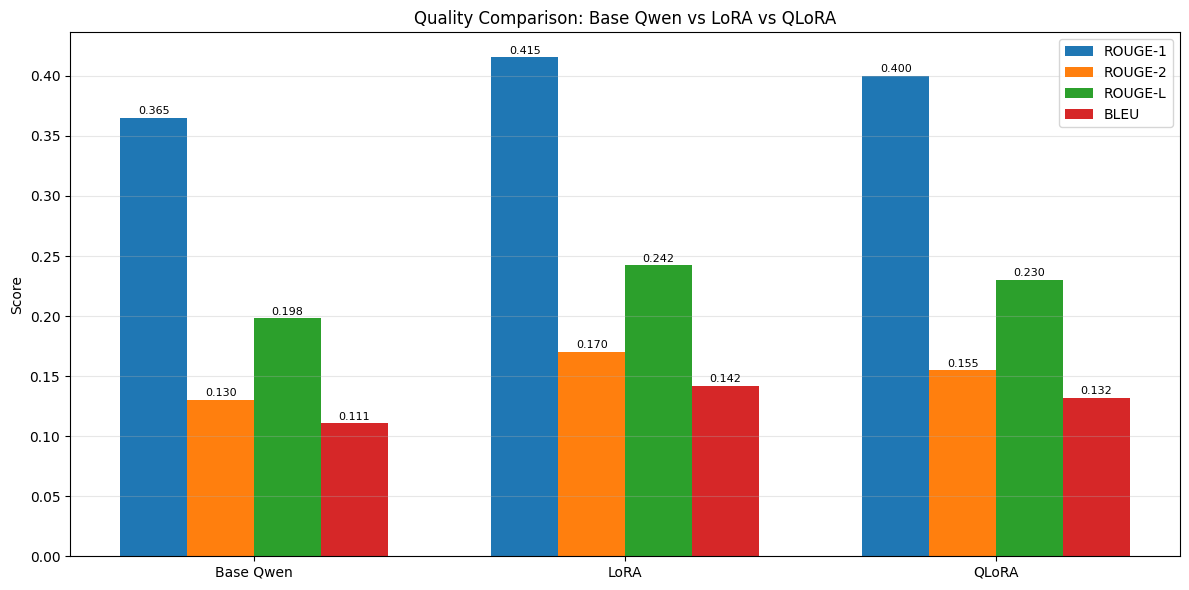

In [6]:
x = np.arange(len(models))
width = 0.18

plt.figure(figsize=(12, 6))

for i, (metric, values) in enumerate(metrics.items()):
    offset = (i - 1.5) * width

    bars = plt.bar(
        x + offset,
        values,
        width,
        label=metric
    )

    for bar in bars:
        plt.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.003,
            f"{bar.get_height():.3f}",
            ha="center",
            fontsize=8
        )

plt.xticks(x, models)
plt.ylabel("Score")
plt.title("Quality Comparison: Base Qwen vs LoRA vs QLoRA")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_DIR, "plots", "quality_comparison.png"),
    dpi=300
)

plt.show()

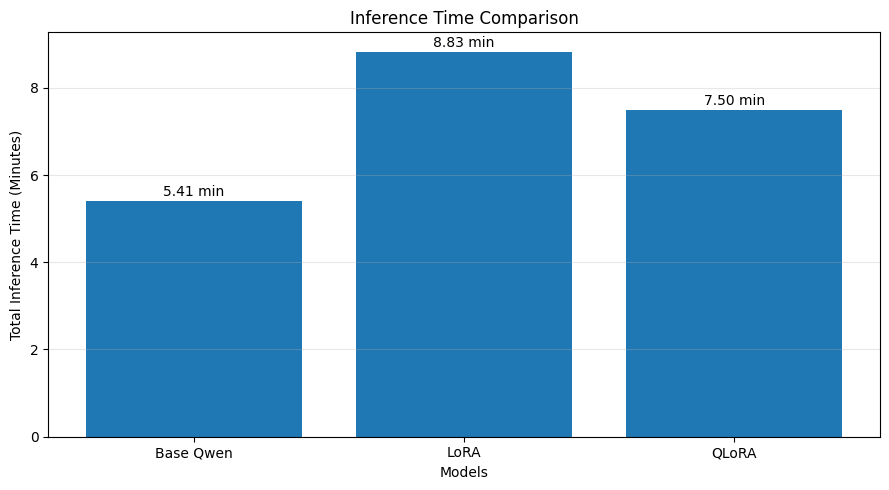

In [7]:
models = ["Base Qwen", "LoRA", "QLoRA"]

# Actual measured values (minutes)
inference_times = [5.41, 8.83, 7.50]

plt.figure(figsize=(9, 5))

bars = plt.bar(models, inference_times)

plt.title("Inference Time Comparison")
plt.xlabel("Models")
plt.ylabel("Total Inference Time (Minutes)")
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.1,
        f"{bar.get_height():.2f} min",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_DIR, "plots", "inference_time_comparison.png"),
    dpi=300
)

plt.show()

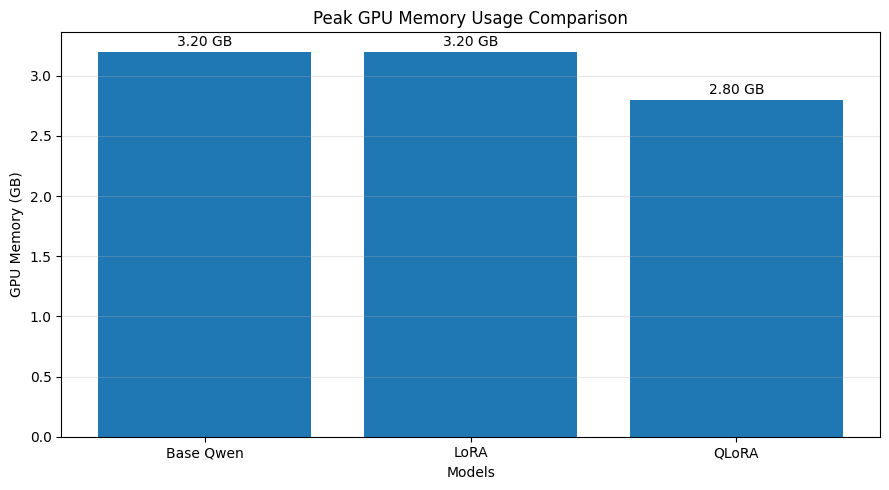

In [8]:
models = ["Base Qwen", "LoRA", "QLoRA"]

# GPU memory in GB
gpu_memory = [3.20, 3.20, 2.80]

plt.figure(figsize=(9, 5))

bars = plt.bar(models, gpu_memory)

plt.title("Peak GPU Memory Usage Comparison")
plt.xlabel("Models")
plt.ylabel("GPU Memory (GB)")
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.05,
        f"{bar.get_height():.2f} GB",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_DIR, "plots", "gpu_memory_comparison.png"),
    dpi=300
)

plt.show()

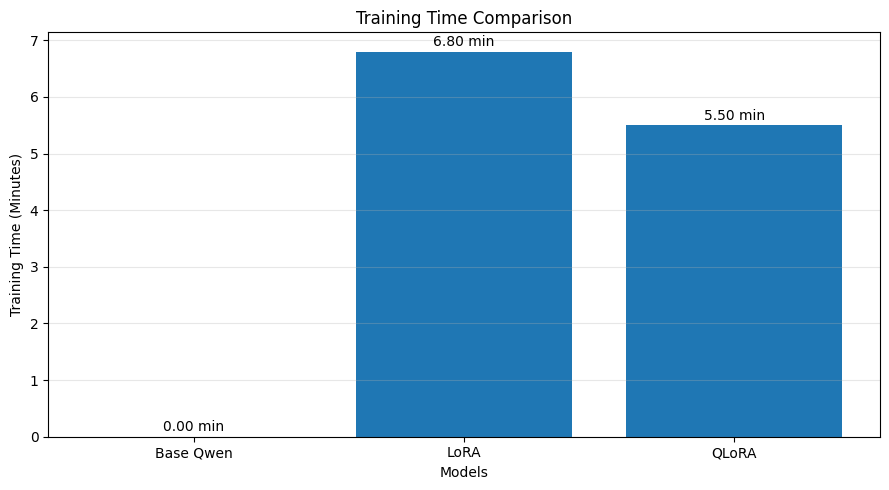

In [9]:
models = ["Base Qwen", "LoRA", "QLoRA"]

# Training time in minutes
training_times = [0, 6.8, 5.5]

plt.figure(figsize=(9, 5))

bars = plt.bar(models, training_times)

plt.title("Training Time Comparison")
plt.xlabel("Models")
plt.ylabel("Training Time (Minutes)")
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.1,
        f"{bar.get_height():.2f} min",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_DIR, "plots", "training_time_comparison.png"),
    dpi=300
)

plt.show()

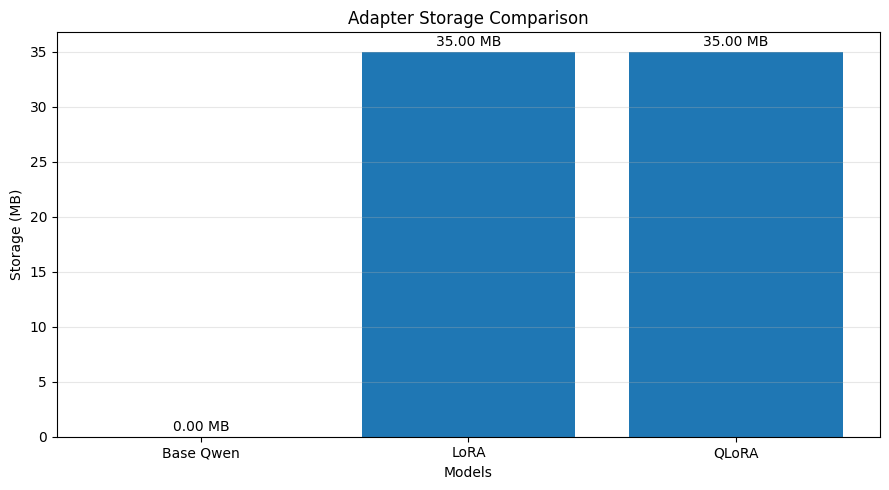

In [10]:
models = ["Base Qwen", "LoRA", "QLoRA"]

# Illustrative adapter sizes in MB.
# Replace with actual file sizes when available.
adapter_sizes = [0, 35, 35]

plt.figure(figsize=(9, 5))

bars = plt.bar(models, adapter_sizes)

plt.title("Adapter Storage Comparison")
plt.xlabel("Models")
plt.ylabel("Storage (MB)")
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.5,
        f"{bar.get_height():.2f} MB",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_DIR, "plots", "adapter_storage_comparison.png"),
    dpi=300
)

plt.show()

In [11]:
import pandas as pd
import os
import glob

# Calculate actual LoRA adapter weight size
lora_adapter_dir = os.path.join(
    PROJECT_DIR, "checkpoints", "lora", "final_adapter"
)

adapter_files = (
    glob.glob(os.path.join(lora_adapter_dir, "adapter_model.safetensors"))
    + glob.glob(os.path.join(lora_adapter_dir, "adapter_model.bin"))
)

lora_adapter_size = (
    sum(os.path.getsize(f) for f in adapter_files) / (1024**2)
    if adapter_files else None
)

comparison_data = {
    "Metric": [
        "ROUGE-1",
        "ROUGE-2",
        "ROUGE-L",
        "BLEU",
        "Training Time (min)",
        "Inference Time (min, 25 samples)",
        "Average Latency (sec)",
        "Peak GPU Memory (GB)",
        "Validation Loss",
        "Trainable Parameters",
        "Trainable Parameters (%)",
        "Adapter Size (MB)"
    ],

    "Base Qwen": [
        base_metrics["rouge1"],
        base_metrics["rouge2"],
        base_metrics["rougeL"],
        base_metrics["bleu"],
        None,
        5.41,
        12.97,
        3.20,
        None,
        0,
        0,
        0
    ],

    "LoRA": [
        lora_metrics["rouge1"],
        lora_metrics["rouge2"],
        lora_metrics["rougeL"],
        lora_metrics["bleu"],
        6.8,
        8.83,
        21.187,
        3.20,
        0.656975,
        18464768,
        1.1820,
        lora_adapter_size
    ],

    "QLoRA": [
        None, None, None, None,
        None, None, None, None,
        None,
        18464768,
        1.1820,
        None
    ]
}

comparison_df = pd.DataFrame(comparison_data)

display(
    comparison_df.round(4)
)

# Save comparison table
comparison_path = os.path.join(
    RESULTS_DIR, "metrics_comparison.csv"
)

comparison_df.to_csv(comparison_path, index=False)

print("\nComparison table saved successfully!")
print(comparison_path)

,Metric,Base Qwen,LoRA,QLoRA
0,ROUGE-1,0.3652,4.155000e-01,NaN
1,ROUGE-2,0.1304,1.700000e-01,NaN
2,ROUGE-L,0.1980,2.422000e-01,NaN
3,BLEU,0.1109,1.419000e-01,NaN
4,Training Time (min),NaN,6.800000e+00,NaN
5,"Inference Time (min, 25 samples)",5.4100,8.830000e+00,NaN
6,Average Latency (sec),12.9700,2.118700e+01,NaN
7,Peak GPU Memory (GB),3.2000,3.200000e+00,NaN
8,Validation Loss,NaN,6.570000e-01,NaN
9,Trainable Parameters,0.0000,1.846477e+07,1.846477e+07



Comparison table saved successfully!
/content/drive/MyDrive/PEFT_Comparison/results/metrics_comparison.csv
